# 01 · Data audit & cleaning
**Business question:** *Can management trust these numbers, and how much of the business can customer analytics actually see?*

Logic lives in `src/cie/ingest.py`, `clean.py`, `audit.py`. This notebook presents the evidence.

In [1]:
import sys, pandas as pd
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
T = ROOT / 'reports' / 'tables'; F = ROOT / 'reports' / 'figures'
def fig(name): display(Image(filename=str(F / f'{name}.png')))

## 1. Data-quality scorecard — every issue in rows **and** pounds

In [2]:
pd.read_csv(T / 'data_quality_scorecard.csv')[['dimension','issue','rows_affected','pct_rows','revenue_affected_gbp','pct_of_gross_sales','treatment']]

,dimension,issue,rows_affected,pct_rows,revenue_affected_gbp,pct_of_gross_sales,treatment
0,Completeness,Missing Customer ID (all lines),235151,0.228,"3,090,394.120",0.151,Cannot attribute to a customer. Excluded from ...
1,Completeness,Missing Description,4382,0.004,0.000,0.000,All are zero-price stock adjustments; no reven...
2,Uniqueness,Invoices duplicated across the two sheets (1–9...,22523,0.021,"377,488.450",0.018,Removed (R1). Otherwise these invoices are cou...
3,Uniqueness,Exact duplicate lines within a sheet,11812,0.011,"54,228.420",0.003,Removed (R2). ASSUMPTION: system double-posts.
4,Validity,Cancellation lines (invoice prefix 'C'),19104,0.018,"-1,462,050.610",-0.071,Kept as negative revenue. Matched reversals fl...
5,Validity,Cancellations matched to the exact sale they r...,6100,0.006,"652,006.630",0.032,Pairs excluded from order counts; revenue nets...
6,Validity,Bad-debt write-off adjustments (prefix 'A'),6,0.000,"-147,614.080",-0.007,Finance item; excluded from customer analytics.
7,Validity,Negative-quantity stock adjustments (damaged/l...,3393,0.003,0.000,0.000,"Inventory events, not sales. Excluded."
8,Validity,Zero-price lines with positive quantity,2621,0.003,0.000,0.000,Free/sample items or keying errors. Excluded f...
9,Consistency,"Non-merchandise stock codes (postage, fees, ma...",5801,0.006,"75,748.711",0.004,Kept for finance reconciliation; excluded from...


**Read-out**
* The two source sheets overlap for 1–9 Dec 2010: every one of those invoices appears twice. Removed.
* 22.8% of lines have no Customer ID, but that is **15.1% of gross sales** — customer analytics sees ~85% of revenue.
* Some very large orders were keyed and cancelled minutes later. They net to zero in revenue but would inflate order counts, so they are matched and flagged (rules R5/R5b) rather than simply netted.

## 2. Cleaning log

In [3]:
pd.read_csv(T / 'cleaning_log.csv')

,rule,description,rows_before,rows_after,rows_removed,note
0,R1,Drop invoices duplicated across the two sheets...,1067371,1044848,22523,"22,523 lines across 1,088 invoices"
1,R2,Drop exact duplicate lines within a sheet,1044848,1033036,11812,"net revenue in removed lines: £54,228"
2,R5,Flag cancellations matched to the sale they re...,1033036,1033036,0,"6,091 of 19,104 cancellation lines matched to ..."
3,R5b,Flag manual ('M') credits that exactly reverse...,1033036,1033036,0,"9 pairs, £39,106 of sales reversed"


## 3. Non-merchandise codes kept for finance, excluded from customer metrics

In [4]:
pd.read_csv(T / 'non_product_codes.csv').head(20)

,item_type,stock_code,lines,net_revenue,example_description
0,postage,POST,2086,"110,430.410",POSTAGE
1,postage,DOT,1425,"309,844.100",DOTCOM POSTAGE
2,manual_adjustment,M,1387,"-83,326.330",MANUAL
3,postage,C2,277,"13,136.000",CARRIAGE
4,discount,D,173,"-12,879.630",DISCOUNT
5,samples,S,101,"-5,991.110",SAMPLES
6,fees,BANK CHARGES,100,"-35,482.249",BANK CHARGES
7,manual_adjustment,ADJUST,67,"6,835.240",ADJUSTMENT BY JOHN ON 26/01/2010 16
8,fees,AMAZONFEE,36,"-221,520.500",AMAZON FEE
9,gift_voucher,gift_0001_30,29,610.090,DOTCOMGIFTSHOP GIFT VOUCHER £30.00


## 4. Revenue bridge — ledger to analytics base (must close to £0)

In [5]:
pd.read_csv(T / 'sql_revenue_bridge.csv')

,step,amount_gbp
0,"1. Cleaned ledger, all lines (net of cancellat...","18,855,533.700"
1,2. Remove bad-debt write-offs (A-invoices),"147,614.080"
2,"3. Remove non-merchandise (postage, fees, manu...","-75,748.710"
3,"4. = Net merchandise revenue, all buyers","18,927,399.070"
4,5. Remove guest / unidentified buyers,"-2,568,806.360"
5,6. Remove product sales reversed via manual cr...,"-39,105.500"
6,"7. = Net merchandise revenue, identified custo...","16,319,487.210"
7,Check: step 4 + 5 + 6 - step 7 (must be 0),-0.000


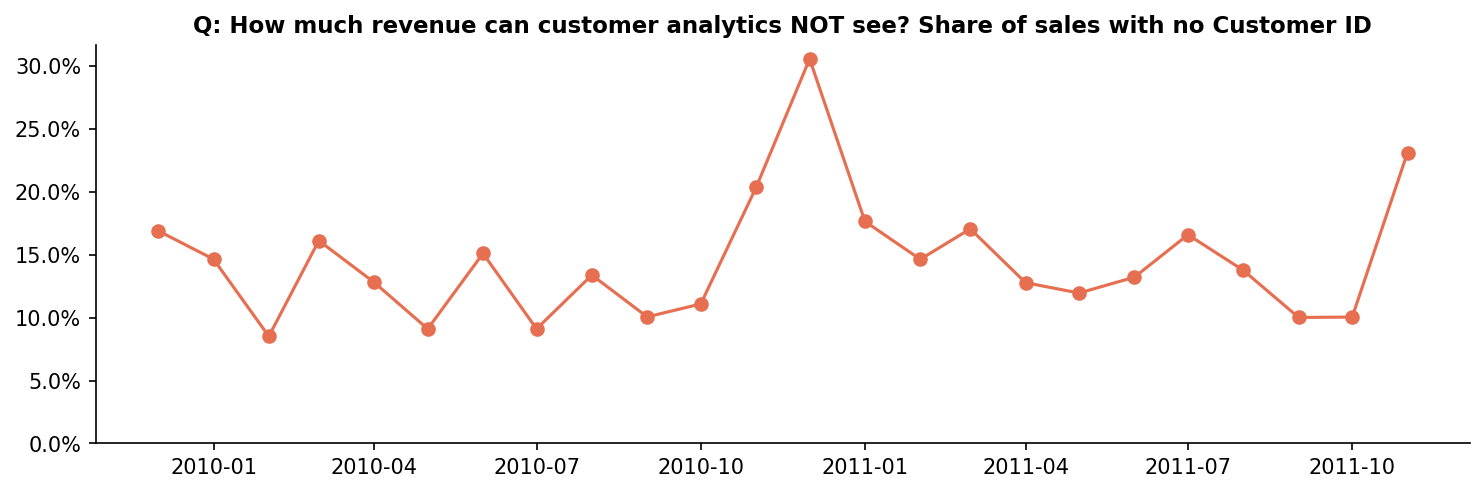

In [6]:
fig('03_missing_customer_id_share')

## What should management do differently?
1. **Make customer identification a KPI.** 15% of sales (and a rising share of growth — see notebook 02) cannot be attributed to a customer, so it cannot be retained, targeted or valued. Require an account/email at checkout or incentivise guest-to-account conversion.
2. **Fix the order-entry process** that allows large orders to be keyed and immediately cancelled; it distorts operational reporting.
3. **Adopt the revenue bridge** as the standard reconciliation between finance revenue and customer-analytics revenue, so the two teams stop debating whose number is right.